# Détection de fraude par carte bancaire : modélisation

**Objectif.** Construire, comparer et évaluer des modèles de détection de fraude, choisir un seuil de décision, estimer l'apport métier et sauvegarder le modèle final.

**Rappel des conclusions de l'EDA**
- cible très déséquilibrée (0,17 % de fraudes) → accuracy inutilisable, on se base sur la **PR-AUC (Average Precision)**, le rappel et la précision ;
- 1 081 doublons exacts conservés → **analyse de sensibilité** à faire ;
- `V1` à `V28` : composantes d'ACP anonymisées, conservées toutes ;
- `Amount` très asymétrique → `Amount_log` ; l'effet de l'heure n'est pas monotone → encodage cyclique ;
- origine de `Time` inconnue, seulement deux jours de données.

**Plan**
1. Configuration, chargement, choix des variables
2. Découpage train / validation / test
3. Fonctions d'évaluation
4. Modèles : baseline, régression logistique, Random Forest, boosting
5. Comparaison (validation, validation croisée, test)
6. Choix du seuil : critère F1 et critère de coût métier
7. Sensibilité aux doublons
8. Interprétation et analyse des erreurs
9. Sauvegarde du modèle et export pour Power BI
10. Conclusion et limites

## 1. Configuration, chargement et variables

In [1]:
import os
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# ----------------------------- Paramètres -----------------------------
SEED = 42
DATA_PATH = "../data/processed/df_enrichi.csv"   # ou le fichier brut creditcard.csv
MODEL_DIR = "../models"
OUT_DIR = "../data/processed"

# Hypothèse de coût métier (à ajuster) : coût d'examen d'une alerte, en unités de Amount
COST_ALERT = 5.0

# Validation croisée : plus robuste mais plus longue (Random Forest)
RUN_CV = True

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
print("Fraudes    :", int(df["Class"].sum()), f"({df['Class'].mean() * 100:.3f} %)")

Dimensions : (284807, 38)
Fraudes    : 492 (0.173 %)


### 1.1 Choix des variables

Les variables du modèle sont construites par **une seule fonction**, réutilisée à l'identique pour l'entraînement et pour la prédiction sur de nouvelles transactions (pas de décalage possible entre les deux).

| Variable | Décision | Raison |
|---|---|---|
| `V1` à `V28` | conservées | signal fort, déjà normalisées par l'ACP |
| `Amount` | remplacée par `Amount_log` | forte asymétrie (transformation fixe, sans fuite) |
| `Time` | **retirée** | secondes depuis le début d'un jeu de données de 2 jours : ne se généralise pas à de nouvelles dates, et un découpage aléatoire permettrait au modèle d'exploiter la proximité temporelle |
| heure du cycle | `Hour_sin`, `Hour_cos` | effet non monotone ; encodage cyclique (23h proche de 0h) ; repose sur l'hypothèse `Time = 0` ≈ minuit |
| `Time_hours`, `Hour_cycle`, `Day`, `Time_bin`, `Amount_category` | retirées | dérivées de `Time` ou de `Amount` (redondantes) |

Le **même jeu de variables** est utilisé pour tous les modèles, afin que la comparaison ne reflète que le modèle.

In [3]:
v_cols = [f"V{i}" for i in range(1, 29)]
FEATURES = v_cols + ["Amount_log", "Hour_sin", "Hour_cos"]


def build_features(raw):
    """Construit les variables du modèle à partir des colonnes brutes (Time, V1..V28, Amount)."""
    X = raw[v_cols].copy()
    X["Amount_log"] = np.log1p(raw["Amount"])
    hour = ((raw["Time"] % 86400) // 3600).astype(int)
    X["Hour_sin"] = np.sin(2 * np.pi * hour / 24)
    X["Hour_cos"] = np.cos(2 * np.pi * hour / 24)
    return X[FEATURES]


X = build_features(df)
y = df["Class"]

print("Nombre de variables :", X.shape[1])
print("Colonnes :", list(X.columns))

Nombre de variables : 31
Colonnes : ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log', 'Hour_sin', 'Hour_cos']


## 2. Découpage train / validation / test

Découpage **stratifié** (même proportion de fraudes partout), identique à celui du notebook précédent :

- **train (60 %)** : entraînement des modèles ;
- **validation (20 %)** : comparaison des modèles et **choix des seuils** ;
- **test (20 %)** : évaluation finale, utilisé uniquement pour rapporter les résultats, jamais pour choisir.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED
)

resume_split = pd.DataFrame({
    "lignes": [len(y_train_model), len(y_val), len(y_test)],
    "fraudes": [int(y_train_model.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=["train", "validation", "test"])
resume_split["taux_fraude_%"] = (resume_split["fraudes"] / resume_split["lignes"] * 100).round(3)
resume_split

,lignes,fraudes,taux_fraude_%
train,170883,295,0.173
validation,56962,99,0.174
test,56962,98,0.172


In [5]:
# Contrôles : aucun chevauchement d'index, mêmes colonnes, pas de cible dans X
print("Chevauchement train/validation :", len(set(X_train_model.index) & set(X_val.index)))
print("Chevauchement train/test       :", len(set(X_train_model.index) & set(X_test.index)))
print("Chevauchement validation/test  :", len(set(X_val.index) & set(X_test.index)))
print("'Class' dans X                 :", "Class" in X.columns)

Chevauchement train/validation : 0
Chevauchement train/test       : 0
Chevauchement validation/test  : 0
'Class' dans X                 : False


## 3. Fonctions d'évaluation

**Choix du seuil par le F1.** Les probabilités d'un modèle ne deviennent une décision (« fraude » / « normale ») qu'à travers un **seuil**. On le choisit sur la validation en maximisant le F1 ; la courbe précision-rappel fournit directement tous les seuils utiles.

**Choix du seuil par le coût métier.** Le F1 donne le même poids à un faux négatif et à un faux positif. Or les deux erreurs ne coûtent pas la même chose :

- une fraude manquée coûte **son montant** (`Amount`) ;
- chaque alerte coûte un temps d'examen : `COST_ALERT` (hypothèse, à ajuster).

$$\text{coût} = \sum_{\text{fraudes manquées}} \text{Amount} \;+\; \text{COST\_ALERT} \times (\text{nombre d'alertes})$$

In [6]:
def best_f1_threshold(y_true, proba):
    """Seuil maximisant le F1, calculé à partir de la courbe précision-rappel."""
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(t[i]), float(f1[i])


def total_cost(y_true, pred, amount, cost_alert=COST_ALERT):
    """Coût total : montants des fraudes manquées + coût d'examen des alertes."""
    y_true, pred, amount = np.asarray(y_true), np.asarray(pred), np.asarray(amount)
    manque = amount[(y_true == 1) & (pred == 0)].sum()
    return float(manque + cost_alert * pred.sum())


def best_cost_threshold(y_true, proba, amount, cost_alert=COST_ALERT):
    """Seuil minimisant le coût métier ; renvoie aussi la courbe coût / seuil."""
    y_true, proba = np.asarray(y_true), np.asarray(proba)
    candidats = np.unique(np.concatenate([np.linspace(0, 1, 1001), proba[y_true == 1]]))
    couts = np.array([total_cost(y_true, (proba >= t).astype(int), amount, cost_alert) for t in candidats])
    i = int(np.argmin(couts))
    return float(candidats[i]), float(couts[i]), pd.DataFrame({"seuil": candidats, "cout": couts})


def evaluate(y_true, proba, thr, amount=None):
    """Métriques à un seuil donné."""
    y_true = np.asarray(y_true)
    pred = (np.asarray(proba) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    out = {
        "seuil": round(float(thr), 4),
        "AP": average_precision_score(y_true, proba),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "precision": precision, "recall": recall, "F1": f1,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }
    if amount is not None:
        out["cout"] = total_cost(y_true, pred, amount)
    return out

## 4. Modèles

Quatre modèles sont comparés, tous entraînés sur le **train uniquement** :

| Modèle | Rôle | Gestion du déséquilibre |
|---|---|---|
| Baseline (`DummyClassifier`) | référence : ce qu'on obtient sans rien apprendre | aucune |
| Régression logistique | modèle linéaire simple, interprétable | `class_weight="balanced"` + `StandardScaler` |
| Random Forest | modèle d'arbres, capte les relations non linéaires | `class_weight="balanced_subsample"` |
| Boosting (XGBoost) | souvent le meilleur sur données tabulaires | `scale_pos_weight` (rapport normales / fraudes) |

Les hyperparamètres sont des valeurs raisonnables **non optimisées** : le but est d'abord de comparer les familles de modèles. Un réglage plus fin est une piste d'amélioration (section 10).

In [7]:
neg, pos = int((y_train_model == 0).sum()), int((y_train_model == 1).sum())

try:
    from xgboost import XGBClassifier
    boost = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=neg / pos, tree_method="hist",
        eval_metric="aucpr", random_state=SEED, n_jobs=-1,
    )
    BOOST_NAME = "XGBoost"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    boost = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_depth=4,
        class_weight="balanced", random_state=SEED,
    )
    BOOST_NAME = "HistGradientBoosting"
    print("xgboost n'est pas installé (pip install xgboost) : HistGradientBoosting est utilisé à la place.")

models = {
    "Baseline (prior)": DummyClassifier(strategy="prior"),
    "Régression logistique": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED,
    ),
    BOOST_NAME: boost,
}
print("Modèles :", list(models))

Modèles : ['Baseline (prior)', 'Régression logistique', 'Random Forest', 'XGBoost']


In [8]:
import time

val_proba, test_proba = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train_model, y_train_model)
    val_proba[name] = model.predict_proba(X_val)[:, 1]
    test_proba[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:<24} entraîné en {time.time() - t0:5.1f} s")

Baseline (prior)         entraîné en   0.0 s
Régression logistique    entraîné en   1.9 s
Random Forest            entraîné en 147.3 s
XGBoost                  entraîné en  12.8 s


## 5. Comparaison des modèles

### 5.1 Sur la validation (critère de choix du modèle)

La métrique principale est l'**Average Precision (AP)**, qui résume la courbe précision-rappel sans fixer de seuil. Le ROC-AUC est donné pour mémoire : avec des fraudes aussi rares, il paraît souvent trop flatteur.

In [9]:
tableau_val = pd.DataFrame({
    name: {
        "AP": average_precision_score(y_val, p),
        "ROC_AUC": roc_auc_score(y_val, p),
    }
    for name, p in val_proba.items()
}).T.sort_values("AP", ascending=False)

print(f"Référence : une AP de {y_val.mean():.4f} correspond au hasard (taux de fraude).")
tableau_val.round(4)

Référence : une AP de 0.0017 correspond au hasard (taux de fraude).


,AP,ROC_AUC
XGBoost,0.8151,0.9732
Random Forest,0.8100,0.9551
Régression logistique,0.6686,0.9761
Baseline (prior),0.0017,0.5000


In [10]:
# Meilleur modèle selon l'AP de validation (hors baseline)
candidats = tableau_val.drop(index="Baseline (prior)")
best_name = candidats["AP"].idxmax()
best_model = models[best_name]
print("Meilleur modèle sur la validation :", best_name, f"(AP = {candidats.loc[best_name, 'AP']:.4f})")

Meilleur modèle sur la validation : XGBoost (AP = 0.8151)


### 5.2 Validation croisée stratifiée (robustesse)

La validation contient peu de fraudes : l'AP varie sensiblement d'un découpage à l'autre. Une validation croisée à 5 plis sur train + validation donne une idée de cette variabilité. Si deux modèles ont des moyennes proches par rapport à l'écart-type, la différence n'est pas fiable.

*Remarque : les doublons peuvent se retrouver dans des plis différents et gonfler légèrement les scores ; la sensibilité aux doublons est étudiée en section 7.*

In [11]:
if RUN_CV:
    X_dev = pd.concat([X_train_model, X_val])
    y_dev = pd.concat([y_train_model, y_val])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    cv_scores = {}
    for name, model in models.items():
        if name == "Baseline (prior)":
            continue
        scores = cross_val_score(clone(model), X_dev, y_dev, scoring="average_precision", cv=cv)
        cv_scores[name] = scores
        print(f"{name:<24} AP = {scores.mean():.4f} ± {scores.std():.4f}")

    cv_table = pd.DataFrame({k: {"AP_moyenne": v.mean(), "AP_ecart_type": v.std()} for k, v in cv_scores.items()}).T
    cv_table.sort_values("AP_moyenne", ascending=False).round(4)
else:
    print("Validation croisée désactivée (RUN_CV = False).")

Régression logistique    AP = 0.7554 ± 0.0370
Random Forest            AP = 0.8434 ± 0.0217
XGBoost                  AP = 0.8373 ± 0.0260


### 5.3 Courbes précision-rappel

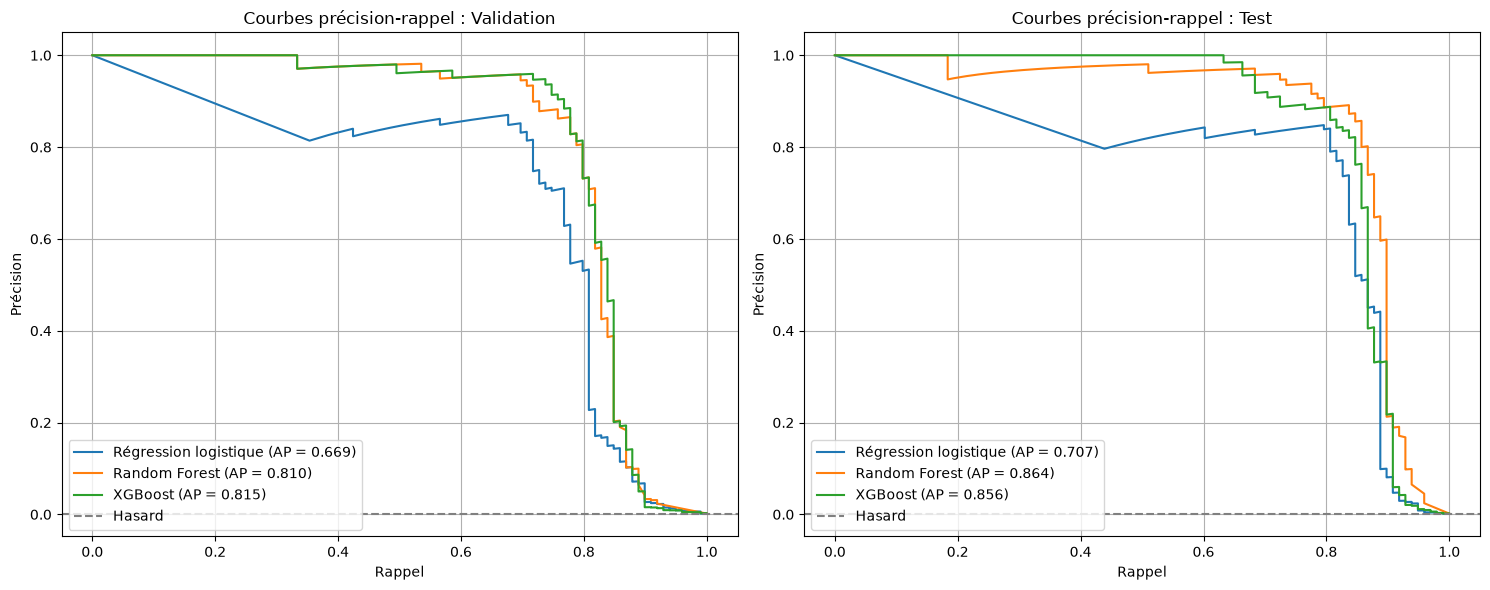

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (titre, y_ref, probas) in zip(
    axes, [("Validation", y_val, val_proba), ("Test", y_test, test_proba)]
):
    for name, p in probas.items():
        if name == "Baseline (prior)":
            continue
        prec, rec, _ = precision_recall_curve(y_ref, p)
        ax.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_ref, p):.3f})")
    ax.axhline(y_ref.mean(), color="gray", linestyle="--", label="Hasard")
    ax.set_title(f"Courbes précision-rappel : {titre}")
    ax.set_xlabel("Rappel")
    ax.set_ylabel("Précision")
    ax.grid(True)
    ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

## 6. Choix du seuil de décision

### 6.1 Seuil maximisant le F1 (choisi sur la validation)

Pour chaque modèle, le seuil est choisi sur la **validation**, puis appliqué **sans modification** au test.

In [14]:
amount_val = df.loc[y_val.index, "Amount"].values
amount_test = df.loc[y_test.index, "Amount"].values

seuils_f1 = {}
lignes = []
for name in models:
    if name == "Baseline (prior)":
        continue
    thr, f1_val = best_f1_threshold(y_val, val_proba[name])
    seuils_f1[name] = thr
    res = evaluate(y_test, test_proba[name], thr, amount_test)
    res["modèle"] = name
    res["F1_validation"] = f1_val
    lignes.append(res)

resultats_test = pd.DataFrame(lignes).set_index("modèle")
cols = ["seuil", "AP", "ROC_AUC", "precision", "recall", "F1", "TP", "FP", "FN", "F1_validation"]
resultats_test[cols].sort_values("AP", ascending=False).round(4)

,seuil,AP,ROC_AUC,precision,recall,F1,TP,FP,FN,F1_validation
modèle,,,,,,,,,,
Random Forest,0.2531,0.8640,0.9772,0.8557,0.8469,0.8513,83,14,15,0.8191
XGBoost,0.9817,0.8561,0.9767,0.8837,0.7755,0.8261,76,10,22,0.8315
Régression logistique,1.0000,0.7073,0.9720,0.8316,0.8061,0.8187,79,16,19,0.7667


**Lecture.** Le F1 de validation et le F1 de test doivent être proches : un grand écart signalerait un seuil trop ajusté sur la validation (celle-ci ne contient qu'une centaine de fraudes, donc le seuil est lui-même incertain).

*Pour mémoire, le notebook précédent obtenait avec la régression logistique (autres variables, dont `Time`) : AP = 0,7247, ROC-AUC = 0,973, et au seuil 0,99 une précision de 50 %, un rappel de 87,76 % et un F1 de 0,637.*

### 6.2 Matrice de confusion du meilleur modèle (test)

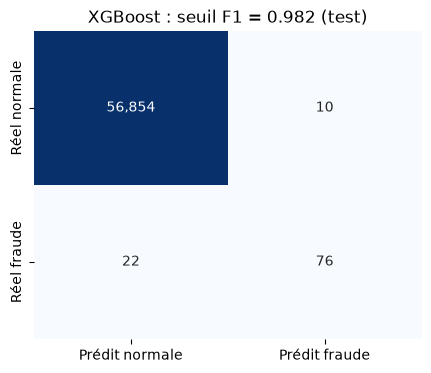

In [15]:
thr_f1 = seuils_f1[best_name]
pred_test = (test_proba[best_name] >= thr_f1).astype(int)
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
    xticklabels=["Prédit normale", "Prédit fraude"],
    yticklabels=["Réel normale", "Réel fraude"],
)
plt.title(f"{best_name} : seuil F1 = {thr_f1:.3f} (test)")
plt.show()

### 6.3 Seuil minimisant le coût métier

Le seuil F1 traite faux positifs et faux négatifs de façon symétrique. Ici, le seuil est choisi pour **minimiser le coût défini en section 3**, sur la validation. On le compare à deux situations de référence :

- **aucun modèle** : toutes les fraudes passent, on perd leurs montants ;
- **alerter toutes les transactions** : on attrape tout, mais chaque transaction coûte `COST_ALERT`.

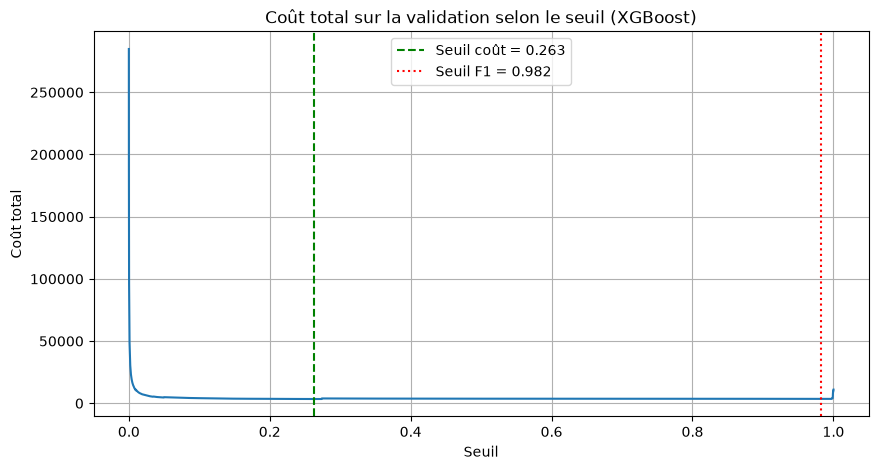

In [16]:
thr_cost, cout_val, courbe_cout = best_cost_threshold(y_val, val_proba[best_name], amount_val)

plt.figure(figsize=(10, 5))
plt.plot(courbe_cout["seuil"], courbe_cout["cout"])
plt.axvline(thr_cost, color="green", linestyle="--", label=f"Seuil coût = {thr_cost:.3f}")
plt.axvline(thr_f1, color="red", linestyle=":", label=f"Seuil F1 = {thr_f1:.3f}")
plt.title(f"Coût total sur la validation selon le seuil ({best_name})")
plt.xlabel("Seuil")
plt.ylabel("Coût total")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
y_test_arr = y_test.values
scenarios = {}

# Aucun modèle / alerter tout
scenarios["Aucun modèle"] = total_cost(y_test_arr, np.zeros(len(y_test_arr), dtype=int), amount_test)
scenarios["Alerter toutes les transactions"] = total_cost(y_test_arr, np.ones(len(y_test_arr), dtype=int), amount_test)

# Seuils F1 et coût, appliqués au test
for label, thr in [("Seuil F1", thr_f1), ("Seuil coût", thr_cost)]:
    pred = (test_proba[best_name] >= thr).astype(int)
    scenarios[label] = total_cost(y_test_arr, pred, amount_test)

bilan = pd.DataFrame({"coût_total": scenarios})
bilan["économie_vs_aucun_modèle"] = scenarios["Aucun modèle"] - bilan["coût_total"]
bilan["économie_%"] = (bilan["économie_vs_aucun_modèle"] / scenarios["Aucun modèle"] * 100).round(1)

detail = pd.DataFrame([
    {"scénario": label, **{k: v for k, v in evaluate(y_test, test_proba[best_name], thr).items()
                           if k in ["seuil", "precision", "recall", "TP", "FP", "FN"]}}
    for label, thr in [("Seuil F1", thr_f1), ("Seuil coût", thr_cost)]
]).set_index("scénario")

print(f"Hypothèse : COST_ALERT = {COST_ALERT} (par alerte). Montants du jeu de test.")
display(bilan.round(1))
display(detail.round(4))

Hypothèse : COST_ALERT = 5.0 (par alerte). Montants du jeu de test.


,coût_total,économie_vs_aucun_modèle,économie_%
Aucun modèle,10644.9,0.0,0.0
Alerter toutes les transactions,284810.0,-274165.1,-2575.5
Seuil F1,2835.6,7809.3,73.4
Seuil coût,2658.5,7986.4,75.0


,seuil,precision,recall,TP,FP,FN
scénario,,,,,,
Seuil F1,0.9817,0.8837,0.7755,76,10,22
Seuil coût,0.2630,0.5120,0.8673,85,81,13


**Attention.** Le seuil « coût » est optimal **sur la validation**. Avec une centaine de fraudes, il n'est pas garanti d'être meilleur sur le test que le seuil F1 : si les coûts sont proches ou inversés, la différence est dans le bruit. Ce qui compte est surtout l'ordre de grandeur de l'économie par rapport à l'absence de modèle.

**Sensibilité à l'hypothèse de coût.** Le résultat dépend de `COST_ALERT`, qui est une hypothèse. Le tableau ci-dessous montre comment le seuil optimal et le compromis précision / rappel évoluent quand le coût d'une alerte augmente : plus une alerte coûte cher, plus le seuil optimal monte et moins on alerte.

In [18]:
lignes = []
for cout_alerte in [1, 5, 20, 50]:
    thr_c, _, _ = best_cost_threshold(y_val, val_proba[best_name], amount_val, cost_alert=cout_alerte)
    pred = (test_proba[best_name] >= thr_c).astype(int)
    res = evaluate(y_test, test_proba[best_name], thr_c)
    sans_modele = total_cost(y_test_arr, np.zeros(len(y_test_arr), dtype=int), amount_test, cout_alerte)
    avec_modele = total_cost(y_test_arr, pred, amount_test, cout_alerte)
    lignes.append({
        "COST_ALERT": cout_alerte, "seuil": round(thr_c, 3),
        "alertes": int(pred.sum()), "precision": res["precision"], "recall": res["recall"],
        "économie_%": round((sans_modele - avec_modele) / sans_modele * 100, 1),
    })

pd.DataFrame(lignes).set_index("COST_ALERT").round(3)

,seuil,alertes,precision,recall,économie_%
COST_ALERT,,,,,
1,0.034,684,0.130,0.908,81.4
5,0.263,166,0.512,0.867,75.0
20,0.997,71,0.944,0.684,41.8
50,0.997,71,0.944,0.684,21.8


## 7. Sensibilité aux doublons

L'EDA a conservé les 1 081 doublons exacts (dont 19 fraudes). Deux risques à mesurer :

1. **Fuite train → test** : une transaction du test existe à l'identique dans le train, le modèle peut alors la « reconnaître » plutôt que généraliser, ce qui gonfle les scores.
2. **Poids des doublons à l'entraînement** : des lignes répétées pèsent plus que les autres.

**Méthode.** Les lignes sont comparées sur les colonnes brutes (`Time`, `V1` à `V28`, `Amount`) via un hachage. On compare, pour le meilleur modèle :

| Scénario | Entraînement | Évaluation |
|---|---|---|
| A | train complet | test complet |
| A' | train complet | test **sans les lignes déjà vues dans le train** |
| B | train **dédoublonné** | test complet |
| B' | train dédoublonné | test sans les lignes déjà vues |

In [19]:
raw_cols = ["Time"] + v_cols + ["Amount"]
h = pd.util.hash_pandas_object(df[raw_cols], index=False)

# 1) Lignes du test présentes à l'identique dans le train
hash_train = set(h.loc[X_train_model.index])
vu_dans_train = h.loc[X_test.index].isin(hash_train).values
print("Lignes du test déjà présentes dans le train :", int(vu_dans_train.sum()),
      f"(dont {int(y_test.values[vu_dans_train].sum())} fraudes)")

# 2) Train dédoublonné
dup_train = h.loc[X_train_model.index].duplicated().values
X_train_dedup, y_train_dedup = X_train_model[~dup_train], y_train_model[~dup_train]
print("Lignes retirées du train (doublons)        :", int(dup_train.sum()),
      f"(dont {int(y_train_model.values[dup_train].sum())} fraudes)")

Lignes du test déjà présentes dans le train : 280 (dont 7 fraudes)
Lignes retirées du train (doublons)        : 415 (dont 9 fraudes)


In [20]:
# Modèle B : même modèle, entraîné sur le train dédoublonné
model_B = clone(best_model).fit(X_train_dedup, y_train_dedup)
proba_val_B = model_B.predict_proba(X_val)[:, 1]
thr_B, _ = best_f1_threshold(y_val, proba_val_B)
proba_test_B = model_B.predict_proba(X_test)[:, 1]

nouveau = ~vu_dans_train
scenarios_dup = {
    "A  : train complet / test complet": (test_proba[best_name], thr_f1, np.ones(len(y_test), dtype=bool)),
    "A' : train complet / test sans lignes vues": (test_proba[best_name], thr_f1, nouveau),
    "B  : train dédoublonné / test complet": (proba_test_B, thr_B, np.ones(len(y_test), dtype=bool)),
    "B' : train dédoublonné / test sans lignes vues": (proba_test_B, thr_B, nouveau),
}

lignes = []
for label, (proba, thr, masque) in scenarios_dup.items():
    res = evaluate(y_test.values[masque], proba[masque], thr)
    lignes.append({
        "scénario": label,
        "lignes_test": int(masque.sum()),
        "fraudes_test": int(y_test.values[masque].sum()),
        "AP": res["AP"], "precision": res["precision"], "recall": res["recall"], "F1": res["F1"],
    })

pd.DataFrame(lignes).set_index("scénario").round(4)

,lignes_test,fraudes_test,AP,precision,recall,F1
scénario,,,,,,
A : train complet / test complet,56962,98,0.8561,0.8837,0.7755,0.8261
A' : train complet / test sans lignes vues,56682,91,0.8418,0.8734,0.7582,0.8118
B : train dédoublonné / test complet,56962,98,0.8594,0.8778,0.8061,0.8404
B' : train dédoublonné / test sans lignes vues,56682,91,0.8456,0.8675,0.7912,0.8276


**Lecture.**
- Si **A' ≈ A**, les lignes partagées entre train et test ne gonflent pas les performances.
- Si **B ≈ A**, supprimer les doublons du train ne change pas le modèle.
- Les écarts sont à comparer à la variabilité observée en validation croisée (section 5.2) : avec une centaine de fraudes en test, de petites différences ne sont pas significatives.

**Résultats.** 280 lignes du test (dont 7 fraudes) existent à l'identique dans le train ; 415 lignes du train (dont 9 fraudes) sont des doublons.

- **A' contre A** : l'AP passe de 0,856 à 0,842 (-0,014) et le rappel de 77,6 % à 75,8 % quand on retire du test les lignes déjà vues. Les lignes partagées entre train et test **gonflent légèrement** les scores, d'environ 1,4 point d'AP.
- **B contre A** : entraîner sur un train dédoublonné donne une AP de 0,859 contre 0,856 et un rappel de 80,6 % contre 77,6 % (79 fraudes détectées au lieu de 76). Retirer les doublons **ne dégrade pas** le modèle.
- **Conclusion** : l'effet des doublons est faible, du même ordre que la variabilité observée en validation croisée (écart-type de 0,02 à 0,03 sur l'AP). Les conclusions du projet ne dépendent donc pas du choix de les conserver. Pour une évaluation plus stricte, les scénarios A' et B' (test sans lignes déjà vues) sont à privilégier.

## 8. Interprétation et analyse des erreurs

### 8.1 Importance des variables (par permutation)

L'importance par permutation mesure la **baisse d'AP** quand les valeurs d'une variable sont mélangées au hasard : plus la baisse est forte, plus le modèle s'appuie sur cette variable. Elle est calculée sur un sous-échantillon de la validation (toutes les fraudes + des transactions normales tirées au hasard) pour limiter le temps de calcul.

*Les `V` étant anonymisées, on peut dire quelles variables comptent, pas ce qu'elles représentent.*

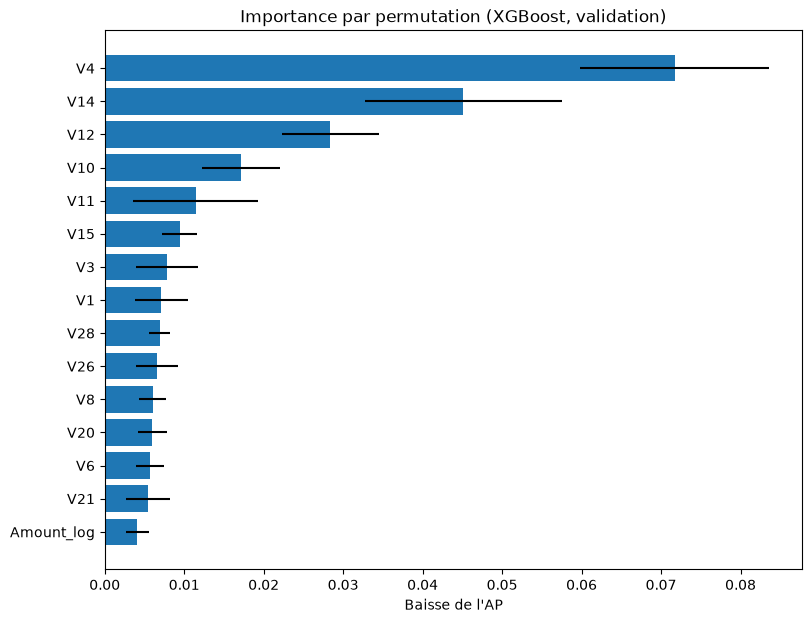

,baisse_AP,ecart_type
V4,0.0717,0.0119
V14,0.0451,0.0124
V12,0.0284,0.0061
V10,0.0171,0.0049
V11,0.0115,0.0079
V15,0.0094,0.0022
V3,0.0078,0.0039
V1,0.0071,0.0033
V28,0.0069,0.0013
V26,0.0066,0.0026


In [21]:
rng = np.random.RandomState(SEED)
idx_fraude = y_val.index[y_val == 1]
idx_normal = rng.choice(y_val.index[y_val == 0], size=min(15000, int((y_val == 0).sum())), replace=False)
idx_ech = np.concatenate([idx_fraude, idx_normal])

perm = permutation_importance(
    best_model, X_val.loc[idx_ech], y_val.loc[idx_ech],
    scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1,
)
importance = pd.DataFrame({
    "baisse_AP": perm.importances_mean, "ecart_type": perm.importances_std
}, index=X_val.columns).sort_values("baisse_AP", ascending=False)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(top.index, top["baisse_AP"], xerr=top["ecart_type"])
plt.title(f"Importance par permutation ({best_name}, validation)")
plt.xlabel("Baisse de l'AP")
plt.show()

importance.head(10).round(4)

**À comparer avec l'EDA.** L'EDA avait repéré `V14`, `V12`, `V10`, `V3`, `V4`, `V11` comme les plus discriminantes individuellement (AUC univariée). Les variables importantes pour le modèle recoupent-elles cette liste ? Un écart n'est pas anormal : l'importance par permutation mesure l'apport **en présence des autres variables**, alors que l'AUC univariée regarde chaque variable seule. Une variable redondante avec une autre peut avoir une importance faible même si elle est discriminante.
`Dans cette ananlyse, nous avons repéré que les variables **V4**, **V14**, **V12, V10 et V11** disposent de la plus grande baisse d'AP donc les plus importants par permutation `

### 8.2 Analyse des erreurs

Quelles fraudes le modèle manque-t-il (faux négatifs), et sont-elles différentes de celles qu'il détecte ?

In [23]:
test_res = df.loc[X_test.index, ["Time", "Amount", "Class"]].copy()
test_res["Hour"] = ((test_res["Time"] % 86400) // 3600).astype(int)
test_res["proba_fraude"] = test_proba[best_name]
test_res["alerte"] = (test_res["proba_fraude"] >= thr_f1).astype(int)
test_res["resultat"] = np.select(
    [
        (test_res["Class"] == 1) & (test_res["alerte"] == 1),
        (test_res["Class"] == 1) & (test_res["alerte"] == 0),
        (test_res["Class"] == 0) & (test_res["alerte"] == 1),
    ],
    ["TP", "FN", "FP"], default="TN",
)

print(test_res["resultat"].value_counts().to_string())
print()
fraudes = test_res[test_res["Class"] == 1]
print("Fraudes détectées (TP) vs manquées (FN) :")
display(fraudes.groupby("resultat")[["Amount", "proba_fraude"]].describe().round(3).T)

resultat
TN    56854
TP       76
FN       22
FP       10

Fraudes détectées (TP) vs manquées (FN) :


resultat                 FN        TP
Amount       count   22.000    76.000
             mean   109.347   108.412
             std    196.676   244.022
             min      1.000     0.000
             25%      1.000     1.000
             50%      4.140    11.505
             75%     99.495   102.917
             max    635.100  1809.680
proba_fraude count   22.000    76.000
             mean     0.361     0.999
             std      0.414     0.003
             min      0.000     0.984
             25%      0.003     0.999
             50%      0.120     1.000
             75%      0.835     1.000
             max      0.981     1.000

In [24]:
manques = fraudes[fraudes["resultat"] == "FN"].sort_values("Amount", ascending=False)
part_montant = manques["Amount"].sum() / fraudes["Amount"].sum() * 100

print(f"Fraudes manquées : {len(manques)} sur {len(fraudes)}")
print(f"Part du montant total des fraudes qui n'est pas récupérée : {part_montant:.1f} %")
manques[["Amount", "Hour", "proba_fraude"]].head(10).round(3)

Fraudes manquées : 22 sur 98
Part du montant total des fraudes qui n'est pas récupérée : 22.6 %


,Amount,Hour,proba_fraude
157918,635.10,6,0.003
623,529.00,0,0.066
68067,519.90,14,0.003
70589,261.87,14,0.933
8972,179.66,3,0.868
14170,99.99,6,0.895
96341,98.01,18,0.001
119714,29.95,20,0.001
149869,18.00,1,0.981
10204,11.39,4,0.657


**Lecture.** Sur les 98 fraudes du test, **22 sont manquées** au seuil F1 (0,982).

- **Les montants ne les distinguent pas des fraudes détectées** : moyenne d'environ 109 contre 108, médiane de 4,14 contre 11,5. Il s'agit surtout de petits montants, mais trois fraudes manquées dépassent 500 (635, 529 et 520), toutes avec une probabilité inférieure ou égale à 0,07. Ensemble, les fraudes manquées représentent **22,6 %** du montant total des fraudes du test.
- **Deux profils** apparaissent, grâce à la comparaison avec le seuil de coût (0,263), qui ne laisse que 13 fraudes manquées :
  - **environ 13 fraudes « invisibles »** : leur probabilité est inférieure à 0,263 (un quart des fraudes manquées sont sous 0,003). Le modèle ne les reconnaît pas : leur comportement n'est pas capté par les variables disponibles ;
  - **environ 9 cas limites** : leur probabilité est comprise entre 0,263 et 0,982. Elles sont rattrapées en baissant le seuil, au prix de 71 fausses alertes supplémentaires (81 au lieu de 10), soit environ 8 fausses alertes pour chaque fraude de plus.
- Les fraudes manquées ne sont donc **pas toutes invisibles** : une partie relève du choix du seuil, une autre d'une limite du modèle.

## 9. Sauvegarde du modèle et export pour Power BI

Le modèle est sauvegardé **avec** la liste de ses variables, ses seuils et ses hypothèses de coût : la fonction `build_features` de la section 1 permet de refaire les variables à partir de colonnes brutes.

In [25]:
os.makedirs(MODEL_DIR, exist_ok=True)

bundle = {
    "model": best_model,
    "model_name": best_name,
    "features": FEATURES,
    "threshold_f1": thr_f1,
    "threshold_cost": thr_cost,
    "cost_alert": COST_ALERT,
    "sklearn_version": sklearn.__version__,
    "notes": "Variables construites par build_features(raw) ; heure déduite de Time % 86400 (hypothèse : Time = 0 ~ minuit).",
}
model_path = os.path.join(MODEL_DIR, "fraud_model.joblib")
joblib.dump(bundle, model_path)
print("Modèle sauvegardé :", model_path)

Modèle sauvegardé : ../models\fraud_model.joblib


In [26]:
# Vérification : recharger le modèle et prédire à partir de colonnes brutes
charge = joblib.load(model_path)

brut = df.loc[X_test.index[:5], ["Time"] + v_cols + ["Amount"]]
proba = charge["model"].predict_proba(build_features(brut))[:, 1]

resultat = pd.DataFrame({
    "Amount": brut["Amount"].values,
    "proba_fraude": proba.round(4),
    "alerte_seuil_F1": (proba >= charge["threshold_f1"]).astype(int),
    "Class_reelle": df.loc[brut.index, "Class"].values,
})
resultat

,Amount,proba_fraude,alerte_seuil_F1,Class_reelle
0,23.00,0.0000,0,0
1,11.85,0.0000,0,0
2,76.07,0.0006,0,0
3,0.99,0.0000,0,0
4,1.50,0.0147,0,0


In [27]:
# Cohérence : mêmes probabilités qu'avant sauvegarde
attendu = test_proba[best_name][:5]
print("Probabilités identiques après rechargement :", np.allclose(proba, attendu))

Probabilités identiques après rechargement : True


In [28]:
# Export pour Power BI : résultats du jeu de test
os.makedirs(OUT_DIR, exist_ok=True)
export = test_res[["Time", "Hour", "Amount", "Class", "proba_fraude", "alerte", "resultat"]].copy()
export["seuil_F1"] = thr_f1
export.to_csv(os.path.join(OUT_DIR, "fraud_powerbi.csv"), index=False)
print("Export Power BI :", os.path.join(OUT_DIR, "fraud_powerbi.csv"), export.shape)

Export Power BI : ../data/processed\fraud_powerbi.csv (56962, 8)


## 10. Conclusion, limites et pistes d'amélioration

### 10.1 Résumé automatique des résultats

La cellule suivante rassemble les chiffres à recopier dans la conclusion.

In [29]:
res_best = evaluate(y_test, test_proba[best_name], thr_f1, amount_test)
base_ap = average_precision_score(y_test, test_proba["Baseline (prior)"])

print(f"Modèle retenu (choisi sur la validation) : {best_name}")
print(f"  AP validation = {tableau_val.loc[best_name, 'AP']:.3f}   |   AP test = {res_best['AP']:.3f}   (baseline : {base_ap:.4f})")
print(f"  ROC-AUC test  = {res_best['ROC_AUC']:.3f}")
print()
print(f"Seuil F1 = {thr_f1:.3f} (choisi sur la validation) -> test :")
print(f"  précision = {res_best['precision']:.1%} ; rappel = {res_best['recall']:.1%} ; F1 = {res_best['F1']:.3f}")
print(f"  {res_best['TP']} fraudes détectées sur {res_best['TP'] + res_best['FN']} ; {res_best['FP']} fausses alertes")
print()
print(f"Seuil coût = {thr_cost:.3f} (COST_ALERT = {COST_ALERT}) -> économie vs aucun modèle : "
      f"{bilan.loc['Seuil coût', 'économie_%']} %")

Modèle retenu (choisi sur la validation) : XGBoost
  AP validation = 0.815   |   AP test = 0.856   (baseline : 0.0017)
  ROC-AUC test  = 0.977

Seuil F1 = 0.982 (choisi sur la validation) -> test :
  précision = 88.4% ; rappel = 77.6% ; F1 = 0.826
  76 fraudes détectées sur 98 ; 10 fausses alertes

Seuil coût = 0.263 (COST_ALERT = 5.0) -> économie vs aucun modèle : 75.0 %



### 10.2 Résultats et conclusion

**Comparaison des modèles** (baseline : AP = 0,0017)

| Modèle | AP validation | AP validation croisée | AP test (seuil F1) |
|---|---|---|---|
| XGBoost | **0,815** | 0,837 ± 0,026 | 0,856 |
| Random Forest | 0,810 | **0,843 ± 0,022** | **0,864** |
| Régression logistique | 0,669 | 0,755 ± 0,037 | 0,707 |

- Les deux modèles d'arbres sont **nettement meilleurs** que la régression logistique, mais **indiscernables entre eux** : l'écart (de 0,005 à 0,008) est très inférieur à l'écart-type de la validation croisée (de 0,02 à 0,03).
- XGBoost est retenu car il a la meilleure AP de validation. Sur le test, le Random Forest obtient des résultats comparables, voire un peu meilleurs (F1 de 0,851 contre 0,826) : le choix n'est **pas modifié a posteriori**, car le test ne sert pas à choisir.

**Seuils et coût** (test, 98 fraudes, `COST_ALERT = 5`)

| | Seuil | Fraudes détectées | Fausses alertes | Précision | Rappel | Économie vs aucun modèle |
|---|---|---|---|---|---|---|
| Seuil F1 | 0,982 | 76 | 10 | 88,4 % | 77,6 % | 73,4 % |
| Seuil coût | 0,263 | 85 | 81 | 51,2 % | 86,7 % | 75,0 % |

- Les deux seuils donnent des **économies très proches** (73,4 % et 75,0 %) : la courbe de coût est plate sur une large plage de seuils, donc le choix précis a peu d'impact financier.
- L'économie dépend fortement de l'**hypothèse de coût d'une alerte** : 81 % pour 1, 75 % pour 5, 42 % pour 20 et 22 % pour 50. Plus une alerte coûte cher, plus le seuil optimal monte (0,034, puis 0,263, puis 0,997) et moins on alerte.

**Doublons** : les lignes du test déjà vues dans le train gonflent légèrement l'AP (environ 0,014) ; supprimer les doublons du train ne dégrade pas le modèle (section 7).

**Variables importantes** : V4, V14, V12, V10 et V11 (importance par permutation). Elles recoupent les premières de l'AUC univariée de l'EDA (V14, V4, V12, V11, V10). Les variables d'heure et `Amount_log` ne figurent pas dans le top 10.

**Erreurs** : 22 fraudes manquées au seuil F1 (22,6 % du montant des fraudes) ; environ 13 sont invisibles pour le modèle (probabilité inférieure à 0,263), environ 9 sont des cas limites rattrapables en baissant le seuil (section 8.2).

> Trois modèles ont été comparés à une baseline. XGBoost est retenu (AP de validation 0,815, AP de test 0,856, contre 0,0017 pour la baseline ; ROC-AUC de test 0,977), mais il est indiscernable du Random Forest. Au seuil choisi sur la validation (F1 = 0,982), il détecte 76 des 98 fraudes du test avec 10 fausses alertes (précision 88,4 %, rappel 77,6 %). En intégrant le coût des erreurs (montants des fraudes manquées et coût d'examen des alertes), le seuil de coût (0,263) détecte 85 fraudes pour 81 fausses alertes et réduit le coût de 75,0 % par rapport à l'absence de modèle, contre 73,4 % pour le seuil F1 : l'écart est faible, et l'économie dépend de l'hypothèse de coût d'alerte. Le choix de conserver ou de supprimer les doublons ne modifie pas les conclusions.

### 10.3 Limites

- **Peu de fraudes** (≈ 100 en validation, ≈ 100 en test) : les métriques et surtout les seuils sont incertains ; de petits écarts entre modèles ne sont pas significatifs (voir l'écart-type en validation croisée).
- **Découpage aléatoire** sur deux jours seulement : un découpage chronologique serait plus réaliste, mais deux jours ne le permettent pas de façon convaincante. Rien ne garantit la généralisation à d'autres périodes.
- **Variables anonymisées** : on mesure leur importance, pas leur signification ; l'ACP a été calculée sur l'ensemble des transactions, y compris celles du test.
- **Hypothèse sur `Time`** (origine ≈ minuit) pour l'heure du cycle.
- **Coût métier hypothétique** : `COST_ALERT` est une valeur supposée ; en situation réelle il faudrait la fixer avec le métier. Le coût d'une fraude est ici assimilé à son montant.
- **Choix du modèle fragile** : XGBoost et Random Forest sont indiscernables (voir 10.2) ; le choix de XGBoost suit la règle fixée à l'avance (meilleure AP de validation) et n'est pas modifié après avoir vu le test.
- **Effet de l'heure instable d'un jour à l'autre** (EDA, section 5.4) : les variables d'heure ne figurent pas parmi les plus importantes du modèle.
- **Hyperparamètres non optimisés.**

### 10.4 Pistes d'amélioration

1. **Régler les hyperparamètres** (recherche aléatoire avec validation croisée, métrique AP).
2. **Choisir le seuil par validation croisée** (prédictions hors-pli sur train + validation) pour s'appuyer sur ≈ 400 fraudes plutôt qu'une centaine.
3. **Calibrer les probabilités** (`CalibratedClassifierCV`) pour que « 0,8 » ressemble réellement à 80 % de risque.
4. **Tester d'autres traitements du déséquilibre** (sous-échantillonnage, SMOTE) **uniquement dans les plis d'entraînement**.
5. **Expliquer les prédictions individuelles** (SHAP).
6. **Surveillance en production** : dérive des données, suivi du taux d'alertes, réentraînement périodique.